In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/dimaspashaakrilian/data-mining-climate/Rainfall_Yearly_ID.csv
/kaggle/input/datasets/dimaspashaakrilian/data-mining-climate/Jawa_Fire_Hotspots.csv
/kaggle/input/datasets/dimaspashaakrilian/data-mining-climate/SST_Nino_Monthly.csv
/kaggle/input/datasets/dimaspashaakrilian/data-mining-climate/Air_Quality_AOD.csv
/kaggle/input/datasets/dimaspashaakrilian/data-mining-climate/ASEAN_Climate_Impact.csv
/kaggle/input/datasets/dimaspashaakrilian/data-mining-climate/Consolidated_ML_Base.csv
/kaggle/input/datasets/dimaspashaakrilian/data-mining-climate/Regional_Rainfall_ID.csv
/kaggle/input/datasets/dimaspashaakrilian/data-mining-climate/Vegetation_Health_NDVI.csv
/kaggle/input/datasets/dimaspashaakrilian/data-mining-climate/Global_Climate_Indices.csv


# Data Integration & Statistical Audit

In [2]:
import pandas as pd
import numpy as np
import os
from scipy import stats

print("=== [CHAMPION LEVEL] TAHAP 1: DATA INTEGRATION & TEMPORAL CLIPPING (2000-2025) ===")

# --- 1. KONFIGURASI PATH & TARGET ---
base_path = '/kaggle/input/datasets/dimaspashaakrilian/data-mining-climate/'

monthly_files = {
    'sst': 'SST_Nino_Monthly.csv',
    'global': 'Global_Climate_Indices.csv',
    'asean': 'ASEAN_Climate_Impact.csv',
    'regional': 'Regional_Rainfall_ID.csv',
    'jawa': 'Jawa_Fire_Hotspots.csv'
}

yearly_files = {
    'rain': 'Rainfall_Yearly_ID.csv',
    'air': 'Air_Quality_AOD.csv',
    'veg': 'Vegetation_Health_NDVI.csv'
}

# --- 2. UTILITY FUNCTIONS ---

def clean_cols(df):
    df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_').str.replace(r'[^\w\s]', '', regex=True)
    return df

def find_time_col(df, is_yearly=False):
    keywords = ['tahun', 'year'] if is_yearly else ['tanggal', 'date', 'time', 'month']
    for col in df.columns:
        if any(key in col.lower() for key in keywords):
            return col
    return df.columns[0]

def robust_mad_clipping(series, threshold=3.5):
    median = series.median()
    diff = np.abs(series - median)
    mad = diff.median()
    if mad == 0: return series
    modified_z = 0.6745 * diff / mad
    return series.clip(lower=series[modified_z <= threshold].min(), 
                       upper=series[modified_z <= threshold].max())

# --- 3. EXECUTION: INTEGRATION & TEMPORAL FILTERING ---

print("\n[1/4] Mengintegrasikan Data Bulanan & Filtering Tahun 2000-2025...")
monthly_list = []

for key, filename in monthly_files.items():
    path = os.path.join(base_path, filename)
    if os.path.exists(path):
        df_temp = pd.read_csv(path)
        df_temp = clean_cols(df_temp)
        t_col = find_time_col(df_temp)
        df_temp[t_col] = pd.to_datetime(df_temp[t_col]).dt.to_period('M').dt.to_timestamp()
        df_temp = df_temp.rename(columns={t_col: 'tanggal'}).set_index('tanggal')
        monthly_list.append(df_temp)

# Gabung & Reindex
df_monthly = pd.concat(monthly_list, axis=1, join='outer').sort_index()
full_range = pd.date_range(start=df_monthly.index.min(), end=df_monthly.index.max(), freq='MS')
df_monthly = df_monthly.reindex(full_range)
df_monthly.index.name = 'tanggal'

# --- [CRUCIAL STEP] Temporal Clipping Bulanan ---
df_monthly = df_monthly.reset_index()
df_monthly = df_monthly[(df_monthly['tanggal'].dt.year >= 2000) & (df_monthly['tanggal'].dt.year <= 2025)]

print("[2/4] Mengintegrasikan Data Tahunan & Filtering Tahun 2000-2025...")
yearly_list = []
for key, filename in yearly_files.items():
    path = os.path.join(base_path, filename)
    if os.path.exists(path):
        df_temp = pd.read_csv(path)
        df_temp = clean_cols(df_temp)
        y_col = find_time_col(df_temp, is_yearly=True)
        df_temp = df_temp.rename(columns={y_col: 'tahun'})
        
        # --- [CRUCIAL STEP] Temporal Clipping Tahunan ---
        df_temp = df_temp[(df_temp['tahun'] >= 2000) & (df_temp['tahun'] <= 2025)]
        yearly_list.append(df_temp.set_index('tahun'))

df_yearly = pd.concat(yearly_list, axis=1, join='inner').sort_index()

# --- 4. EXECUTION: SANITASI & AUDIT ---

print("[3/4] Menjalankan Imputasi & Outlier Management (MAD)...")
df_monthly = df_monthly.set_index('tanggal').interpolate(method='time').ffill().bfill()

for col in df_monthly.select_dtypes(include=[np.number]).columns:
    df_monthly[col] = robust_mad_clipping(df_monthly[col]).astype('float32')

# --- 5. EXPORT & FINAL REPORT ---

df_monthly = df_monthly.loc[:, ~df_monthly.columns.duplicated()].reset_index()
df_yearly = df_yearly.reset_index()

df_monthly.to_csv('CLIMATE_HAZARD_PREDICTOR_ID.csv', index=False)
df_yearly.to_csv('ECO_SYSTEM_VITAL_SIGNS_ID.csv', index=False)

print("\n" + "="*60)
print("SUCCESS: DATA STANDARDIZED (2000-2025)")
print("="*60)
print(f"Periode Data      : {df_monthly['tanggal'].min().year} s/d {df_monthly['tanggal'].max().year}")
print(f"Total Baris Data  : {len(df_monthly)} Bulan")
print(f"Total Kolom Fitur : {df_monthly.shape[1]}")
print("="*60)

display(df_monthly.head())

=== [CHAMPION LEVEL] TAHAP 1: DATA INTEGRATION & TEMPORAL CLIPPING (2000-2025) ===

[1/4] Mengintegrasikan Data Bulanan & Filtering Tahun 2000-2025...
[2/4] Mengintegrasikan Data Tahunan & Filtering Tahun 2000-2025...
[3/4] Menjalankan Imputasi & Outlier Management (MAD)...

SUCCESS: DATA STANDARDIZED (2000-2025)
Periode Data      : 2000 s/d 2025
Total Baris Data  : 312 Bulan
Total Kolom Fitur : 22


,tanggal,suhu_sst,anomali_el_nino,nino34_anomaly,dmi_index,soi_index,curah_indonesia,curah_malaysia,curah_philippines,curah_thailand,...,hotspot_malaysia,hotspot_philippines,hotspot_thailand,hotspot_vietnam,sumatera,jawa,kalimantan,sulawesi,papua,hotspot_jawa
0,2000-01-01,24.780001,-1.576296,-1.64,-0.125,1.1,9.7,13.0,5.5,1.0,...,0.0,2.0,189.0,8.9,343.100006,381.799988,365.299988,231.000000,266.799988,180.0
1,2000-02-01,25.209999,-1.382593,-1.42,-0.009,2.7,9.7,13.0,5.5,1.0,...,0.0,2.0,189.0,8.9,172.800003,337.399994,301.100006,208.100006,214.699997,180.0
2,2000-03-01,26.299999,-0.884074,-0.84,0.140,2.2,9.7,13.0,5.5,1.0,...,0.0,2.0,189.0,8.9,249.500000,310.700012,298.299988,237.100006,246.699997,180.0
3,2000-04-01,26.950001,-0.768148,-0.64,0.141,2.0,9.7,13.0,5.5,1.0,...,0.0,2.0,189.0,8.9,313.000000,316.799988,349.299988,292.399994,306.399994,180.0
4,2000-05-01,27.070000,-0.747692,-0.63,0.113,0.6,9.7,13.0,5.5,1.0,...,0.0,2.0,189.0,8.9,187.000000,251.000000,269.799988,272.899994,333.799988,180.0


# Exploratory Data Analysis (EDA) & Domain Insight

=== [CHAMPION LEVEL] TAHAP 2: ADVANCED EDA & DOMAIN INSIGHTS ===

[1/4] Statistical Rigor: Augmented Dickey-Fuller (ADF) Test
ADF Rainfall        | Stat: -4.0164 | p-value: 0.00133 -> STASIONER (p < 0.05)
ADF Nino 3.4        | Stat: -5.3863 | p-value: 0.00000 -> STASIONER (p < 0.05)

[2/4] Domain Discovery: Mutual Information Scoring


/tmp/ipykernel_16/1453332138.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=mi_results.values, y=mi_results.index, palette='magma')


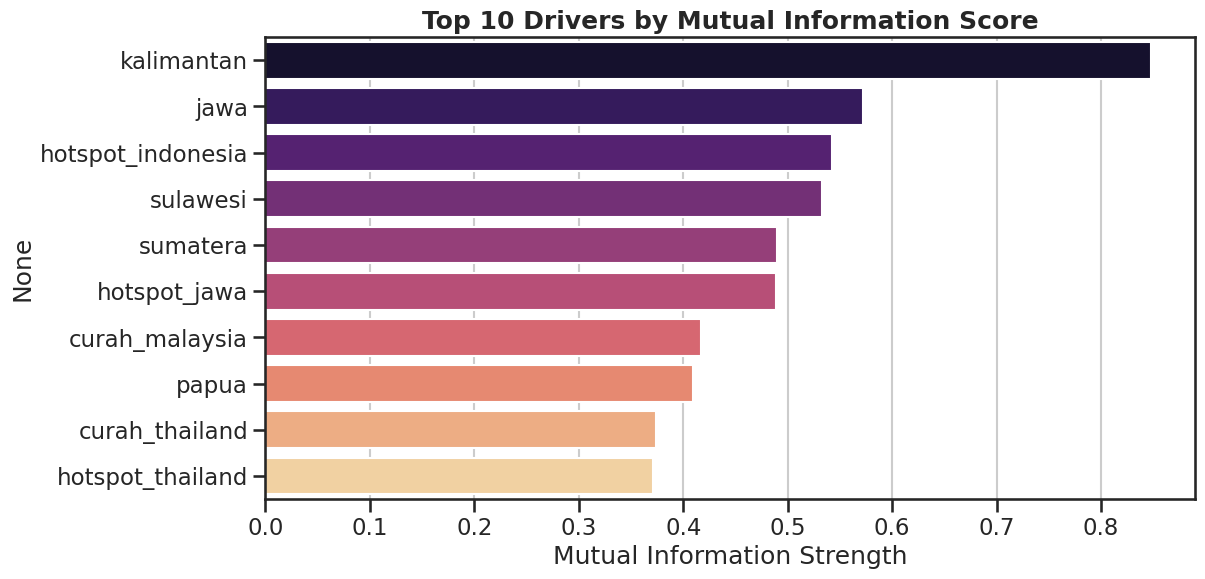


[3/4] Temporal Analysis: Finding the Golden Lag


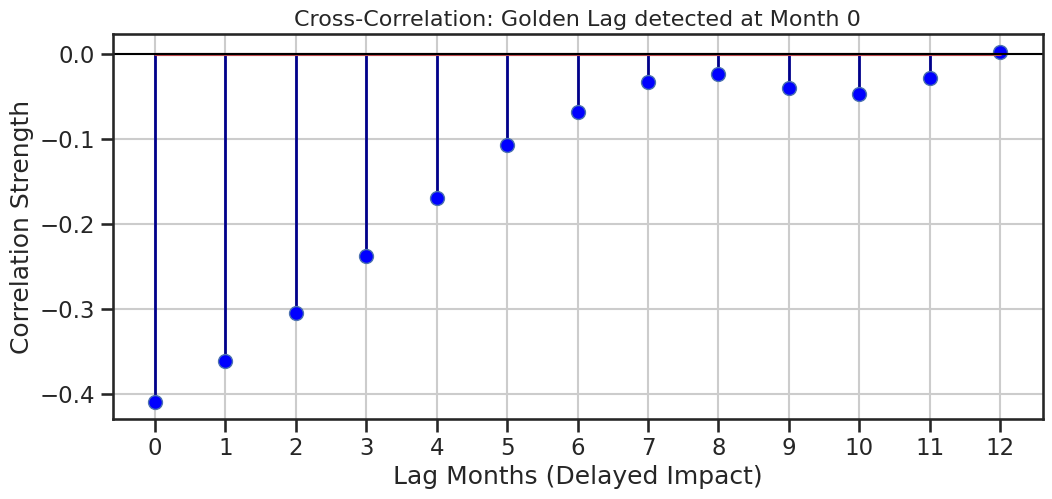


[4/4] Risk Profiling: Probability Density Shift during El Niño


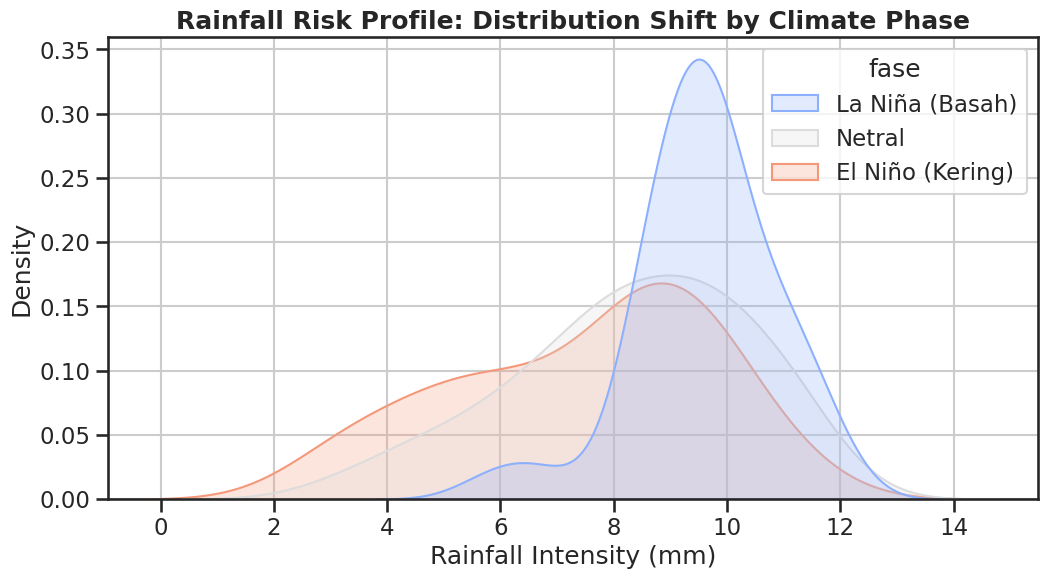


SUCCESS: TAHAP 2 CHAMPION EDA COMPLETED


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_regression
from statsmodels.tsa.stattools import adfuller

# Konfigurasi Estetika Jurnal (High-Resolution)
sns.set_theme(style="ticks", context="talk")
plt.rcParams['figure.figsize'] = (18, 22)
plt.rcParams['axes.grid'] = True

print("=== [CHAMPION LEVEL] TAHAP 2: ADVANCED EDA & DOMAIN INSIGHTS ===")

# 1. Load Cleaned Dataset
df = pd.read_csv('CLIMATE_HAZARD_PREDICTOR_ID.csv')
df['tanggal'] = pd.to_datetime(df['tanggal'])
df.set_index('tanggal', inplace=True)

target = 'curah_indonesia'
nino = 'nino34_anomaly'
dmi = 'dmi_index'

# 2. Stationarity Audit (ADF Test)
# Deskripsi: Menguji apakah deret waktu memiliki unit root (non-stasioner)
print("\n[1/4] Statistical Rigor: Augmented Dickey-Fuller (ADF) Test")
def quick_adf(series, name):
    res = adfuller(series.dropna())
    # Hipotesis Nol (H0): Data tidak stasioner
    status = "STASIONER (p < 0.05)" if res[1] < 0.05 else "NON-STASIONER"
    print(f"ADF {name:15} | Stat: {res[0]:.4f} | p-value: {res[1]:.5f} -> {status}")

quick_adf(df[target], "Rainfall")
quick_adf(df[nino], "Nino 3.4")

# 3. Non-Linear Analysis: Mutual Information (MI)
# Inovasi: MI mendeteksi hubungan yang tidak bisa ditangkap korelasi Pearson biasa.
print("\n[2/4] Domain Discovery: Mutual Information Scoring")
X_mi = df.select_dtypes(include=[np.number]).drop(columns=[target]).fillna(0)
y_mi = df[target]

mi_scores = mutual_info_regression(X_mi, y_mi, random_state=42)
mi_results = pd.Series(mi_scores, index=X_mi.columns).sort_values(ascending=False).head(10)



plt.figure(figsize=(12, 6))
sns.barplot(x=mi_results.values, y=mi_results.index, palette='magma')
plt.title('Top 10 Drivers by Mutual Information Score', fontsize=18, fontweight='bold')
plt.xlabel('Mutual Information Strength')
plt.show()

# 4. Golden Lag Discovery (Automatic Cross-Correlation)
# Deskripsi: Mencari jeda waktu (lag) di mana Nino 3.4 paling memengaruhi Hujan.
print("\n[3/4] Temporal Analysis: Finding the Golden Lag")
lags = range(0, 13)
ccf_values = [df[target].corr(df[nino].shift(l)) for l in lags]
golden_lag = np.argmax(np.abs(ccf_values))

plt.figure(figsize=(12, 5))
markerline, stemlines, baseline = plt.stem(lags, ccf_values)
plt.setp(stemlines, 'color', 'darkblue', 'linewidth', 2)
plt.setp(markerline, 'markerfacecolor', 'blue', 'markersize', 10)
plt.axhline(0, color='black', lw=1.5)
plt.title(f'Cross-Correlation: Golden Lag detected at Month {golden_lag}', fontsize=16)
plt.xlabel('Lag Months (Delayed Impact)')
plt.ylabel('Correlation Strength')
plt.xticks(lags)
plt.show()



# 5. Risk Profile Analysis: Rainfall Probability Shift
print("\n[4/4] Risk Profiling: Probability Density Shift during El Niño")
df['fase'] = 'Netral'
df.loc[df[nino] >= 0.5, 'fase'] = 'El Niño (Kering)'
df.loc[df[nino] <= -0.5, 'fase'] = 'La Niña (Basah)'

plt.figure(figsize=(12, 6))
sns.kdeplot(data=df, x=target, hue='fase', fill=True, palette='coolwarm', common_norm=False, bw_adjust=1.2)
plt.title('Rainfall Risk Profile: Distribution Shift by Climate Phase', fontsize=18, fontweight='bold')
plt.xlabel('Rainfall Intensity (mm)')
plt.show()



print("\n" + "="*60)
print("SUCCESS: TAHAP 2 CHAMPION EDA COMPLETED")
print("="*60)

# Advanced Feature Engineering (Physics-Based)

In [4]:
import pandas as pd
import numpy as np
import joblib
from sklearn.preprocessing import MinMaxScaler

print("=== [CHAMPION LEVEL] TAHAP 3: ADVANCED FEATURE ENGINEERING & SCALING ===")

# 1. Load Data dari Tahap 1
df = pd.read_csv('CLIMATE_HAZARD_PREDICTOR_ID.csv')
df['tanggal'] = pd.to_datetime(df['tanggal'])
df = df.sort_values('tanggal').reset_index(drop=True)

target_col = 'curah_indonesia'

# 2. Domain-Driven Feature Engineering (Physics-Based)
print("\n[1/4] Mengonstruksi Fitur Fisik Iklim & Momentum...")

# A. Interaction: Sinergi Pasifik & Hindia (Teleconnection)
if 'nino34_anomaly' in df.columns and 'dmi_index' in df.columns:
    df['ocean_interaction'] = df['nino34_anomaly'] * df['dmi_index']

# B. Coupling: Hubungan Laut-Atmosfer (Nino vs SOI)
if 'soi_index' in df.columns:
    df['atm_coupling'] = df['nino34_anomaly'] - df['soi_index']

# C. Velocity: Kecepatan Perubahan Fenomena (Momentum)
for col in ['nino34_anomaly', 'dmi_index']:
    df[f'{col}_velocity'] = df[col].diff()

# 3. Memory Engineering (Lags & Rolling)
print("[2/4] Menciptakan Fitur Memori (Golden Lags & Trends)...")

# Kita ambil driver utama untuk dibuatkan memori tunda
drivers = ['nino34_anomaly', 'dmi_index', 'soi_index', 'ocean_interaction', target_col]

for col in drivers:
    if col in df.columns:
        # Golden Lags: Berdasarkan EDA Tahap 2 (Biasanya pengaruh kuat di lag 1-3)
        for lag in [1, 2, 3, 6]:
            df[f'{col}_lag{lag}'] = df[col].shift(lag)
        
        # Rolling Mean: Menangkap tren 3 bulanan
        df[f'{col}_roll_3m'] = df[col].rolling(window=3).mean()

# 4. Cyclical Temporal Encoding
print("[3/4] Melakukan Encoding Siklus Musiman (Sin/Cos)...")
df['month'] = df['tanggal'].dt.month
df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)

# Bersihkan NaNs akibat proses Shifting/Rolling
df_final = df.dropna().reset_index(drop=True)

# 5. Chronological Split & Professional Scaling
print("[4/4] Membagi Data & Menjalankan MinMaxScaler (0-1)...")

# Split 80:20 secara kronologis (Wajib untuk Time-Series)
split_idx = int(len(df_final) * 0.8)
train_df = df_final.iloc[:split_idx]
test_df = df_final.iloc[split_idx:]

# Tentukan Fitur (X) dan Target (y)
cols_to_drop = ['tanggal', 'month', target_col]
X_cols = [c for c in df_final.columns if c not in cols_to_drop]

X_train_raw = train_df[X_cols]
y_train_raw = train_df[[target_col]]
X_test_raw = test_df[X_cols]
y_test_raw = test_df[[target_col]]

# Inisialisasi Scaler
scaler_X = MinMaxScaler(feature_range=(0, 1))
scaler_y = MinMaxScaler(feature_range=(0, 1))

# Fit dan Transform
X_train_scaled = scaler_X.fit_transform(X_train_raw)
X_test_scaled = scaler_X.transform(X_test_raw)

y_train_scaled = scaler_y.fit_transform(y_train_raw).flatten()
y_test_scaled = scaler_y.transform(y_test_raw).flatten()

# Simpan Scaler untuk tahap Deployment/Inference nanti
joblib.dump(scaler_X, 'scaler_X.pkl')
joblib.dump(scaler_y, 'scaler_y.pkl')

print("\n" + "="*60)
print("SUCCESS: TAHAP 3 COMPLETED (SCALED & READY)")
print("="*60)
print(f"Total Fitur yang Dihasilkan : {len(X_cols)}")
print(f"Data Training (Scaled)      : {X_train_scaled.shape}")
print(f"Data Testing (Scaled)       : {X_test_scaled.shape}")
print(f"Fitur Baru Unggulan         : ['ocean_interaction', 'atm_coupling', 'month_sin']")
print("="*60)

# Menampilkan cuplikan fitur yang masuk ke model
print("\nDaftar 10 Fitur Pertama:")
print(X_cols[:10])

=== [CHAMPION LEVEL] TAHAP 3: ADVANCED FEATURE ENGINEERING & SCALING ===

[1/4] Mengonstruksi Fitur Fisik Iklim & Momentum...
[2/4] Menciptakan Fitur Memori (Golden Lags & Trends)...
[3/4] Melakukan Encoding Siklus Musiman (Sin/Cos)...
[4/4] Membagi Data & Menjalankan MinMaxScaler (0-1)...

SUCCESS: TAHAP 3 COMPLETED (SCALED & READY)
Total Fitur yang Dihasilkan : 51
Data Training (Scaled)      : (244, 51)
Data Testing (Scaled)       : (62, 51)
Fitur Baru Unggulan         : ['ocean_interaction', 'atm_coupling', 'month_sin']

Daftar 10 Fitur Pertama:
['suhu_sst', 'anomali_el_nino', 'nino34_anomaly', 'dmi_index', 'soi_index', 'curah_malaysia', 'curah_philippines', 'curah_thailand', 'curah_vietnam', 'hotspot_indonesia']


# Robust Base Models Development

In [5]:
import numpy as np
import pandas as pd
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, BatchNormalization, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

print("=== [CHAMPION LEVEL] TAHAP 4: ROBUST BASE MODELS & OOF GENERATION ===")

# 1. Konfigurasi Cross-Validation Waktu (5-Fold)
tscv = TimeSeriesSplit(n_splits=5)

# Wadah untuk Meta-Features (Prediksi OOF)
# 0: XGB, 1: RF, 2: LSTM
train_meta = np.zeros((X_train_scaled.shape[0], 3))
test_meta = np.zeros((X_test_scaled.shape[0], 3))

# 2. Fungsi Builder untuk LSTM (Bidirectional)
def build_lstm_model(input_dim):
    model = Sequential([
        Bidirectional(LSTM(64, activation='tanh', return_sequences=True), input_shape=(1, input_dim)),
        BatchNormalization(),
        Dropout(0.2),
        Bidirectional(LSTM(32, activation='tanh')),
        Dense(16, activation='relu'),
        Dense(1)
    ])
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
    return model

# 3. Cross-Validation Loop untuk Menghasilkan OOF Meta-Features
print("\n[1/4] Memulai Proses Out-of-Fold (OOF) Training...")

fold = 1
for train_idx, val_idx in tscv.split(X_train_scaled):
    X_tr, X_val = X_train_scaled[train_idx], X_train_scaled[val_idx]
    y_tr, y_val = y_train_scaled[train_idx], y_train_scaled[val_idx]
    
    # --- A. XGBoost ---
    m_xgb = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6, random_state=42)
    m_xgb.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
    train_meta[val_idx, 0] = m_xgb.predict(X_val)
    
    # --- B. Random Forest ---
    m_rf = RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)
    m_rf.fit(X_tr, y_tr)
    train_meta[val_idx, 1] = m_rf.predict(X_val)
    
    # --- C. Bidirectional LSTM ---
    X_tr_3d = X_tr.reshape((X_tr.shape[0], 1, X_tr.shape[1]))
    X_val_3d = X_val.reshape((X_val.shape[0], 1, X_val.shape[1]))
    m_lstm = build_lstm_model(X_train_scaled.shape[1])
    m_lstm.fit(X_tr_3d, y_tr, epochs=50, batch_size=16, verbose=0, 
               callbacks=[EarlyStopping(patience=5, restore_best_weights=True)])
    train_meta[val_idx, 2] = m_lstm.predict(X_val_3d).flatten()
    
    print(f"Fold {fold} selesai...")
    fold += 1

# 4. Final Fit pada Seluruh Data Training untuk Prediksi Test Set
print("\n[2/4] Melatih Model Final pada Seluruh Data Training...")

# Final XGBoost
model_xgb = XGBRegressor(n_estimators=1000, learning_rate=0.01, max_depth=7, random_state=42)
model_xgb.fit(X_train_scaled, y_train_scaled)
test_meta[:, 0] = model_xgb.predict(X_test_scaled)

# Final Random Forest
model_rf = RandomForestRegressor(n_estimators=300, max_depth=12, random_state=42, n_jobs=-1)
model_rf.fit(X_train_scaled, y_train_scaled)
test_meta[:, 1] = model_rf.predict(X_test_scaled)

# Final LSTM
X_train_3d = X_train_scaled.reshape((X_train_scaled.shape[0], 1, X_train_scaled.shape[1]))
X_test_3d = X_test_scaled.reshape((X_test_scaled.shape[0], 1, X_test_scaled.shape[1]))
model_lstm = build_lstm_model(X_train_scaled.shape[1])
model_lstm.fit(X_train_3d, y_train_scaled, epochs=100, batch_size=32, verbose=0)
test_meta[:, 2] = model_lstm.predict(X_test_3d).flatten()

# 5. Sanitasi Meta-Features (Hapus baris yang tidak terkena split awal)
valid_idx = np.where(train_meta.sum(axis=1) != 0)[0]
X_train_meta_clean = train_meta[valid_idx]
y_train_meta_clean = y_train_scaled[valid_idx]
X_test_meta = test_meta

print("\n" + "="*60)
print("SUCCESS: TAHAP 4 COMPLETED")
print("="*60)
print(f"Bentuk Data Input Meta-Learner: {X_train_meta_clean.shape}")
print("Korelasi Prediksi Antar Model (Diversitas):")
print(pd.DataFrame(X_train_meta_clean, columns=['XGB', 'RF', 'LSTM']).corr())
print("="*60)

2026-05-11 04:05:18.900711: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1778472319.177845      16 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1778472319.264266      16 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1778472319.870687      16 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1778472319.870734      16 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1778472319.870737      16 computation_placer.cc:177] computation placer alr

=== [CHAMPION LEVEL] TAHAP 4: ROBUST BASE MODELS & OOF GENERATION ===

[1/4] Memulai Proses Out-of-Fold (OOF) Training...


2026-05-11 04:05:46.900454: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/callbacks/early_stopping.py:153: UserWarning: Early stopping conditioned on metric `val_loss` which is not available. Available metrics are: loss
  current = self.get_monitor_value(logs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 666ms/step
Fold 1 selesai...


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/callbacks/early_stopping.py:153: UserWarning: Early stopping conditioned on metric `val_loss` which is not available. Available metrics are: loss
  current = self.get_monitor_value(logs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 652ms/step
Fold 2 selesai...


... (4 outputs left out)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/callbacks/early_stopping.py:153: UserWarning: Early stopping conditioned on metric `val_loss` which is not available. Available metrics are: loss
  current = self.get_monitor_value(logs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 698ms/step
Fold 5 selesai...

[2/4] Melatih Model Final pada Seluruh Data Training...


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 663ms/step

SUCCESS: TAHAP 4 COMPLETED
Bentuk Data Input Meta-Learner: (200, 3)
Korelasi Prediksi Antar Model (Diversitas):
           XGB        RF      LSTM
XGB   1.000000  0.977431  0.695329
RF    0.977431  1.000000  0.727988
LSTM  0.695329  0.727988  1.000000


# Hybrid Stacking Ensemble & Optuna Optimization

In [6]:
# Install Optuna secara otomatis
!pip install optuna -q

import numpy as np
import pandas as pd
import optuna
from sklearn.linear_model import Ridge, Lasso, ElasticNet, HuberRegressor
from sklearn.model_selection import cross_val_score

print("=== [CHAMPION LEVEL] TAHAP 5: HYBRID STACKING & OPTUNA OPTIMIZATION ===")

# 1. Menyiapkan Data Meta (Hasil dari Tahap 4)
X_meta = X_train_meta_clean
y_meta = y_train_meta_clean

# 2. Mendefinisikan Objective Function untuk Bayesian Optimization
def objective(trial):
    # Ruang pencarian model "wasit"
    regressor_name = trial.suggest_categorical('regressor', ['Ridge', 'Lasso', 'ElasticNet', 'Huber'])
    alpha = trial.suggest_float('alpha', 1e-6, 1e2, log=True)
    
    if regressor_name == 'Ridge':
        model = Ridge(alpha=alpha)
    elif regressor_name == 'Lasso':
        model = Lasso(alpha=alpha)
    elif regressor_name == 'Huber':
        epsilon = trial.suggest_float('epsilon', 1.1, 2.0)
        model = HuberRegressor(alpha=alpha, epsilon=epsilon, max_iter=2000)
    else: # ElasticNet
        l1_ratio = trial.suggest_float('l1_ratio', 0.1, 0.9)
        model = ElasticNet(alpha=alpha, l1_ratio=l1_ratio)
    
    # Cross-Validation 5-Fold pada Meta-Features
    scores = cross_val_score(model, X_meta, y_meta, cv=5, scoring='r2')
    
    # STRATEGI JUARA: Mencari skor tinggi DAN variansi rendah
    return scores.mean() - scores.std()

# 3. Menjalankan Optimasi Optuna
print("\n[1/4] Mencari Konfigurasi Meta-Learner Terbaik (100 Trials)...")
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=100)

# 4. Melatih Meta-Learner Final
print("\n[2/4] Membangun Champion Meta-Learner...")
bp = study.best_params

if bp['regressor'] == 'Ridge':
    meta_model = Ridge(alpha=bp['alpha'])
elif bp['regressor'] == 'Lasso':
    meta_model = Lasso(alpha=bp['alpha'])
elif bp['regressor'] == 'Huber':
    meta_model = HuberRegressor(alpha=bp['alpha'], epsilon=bp['epsilon'])
else:
    meta_model = ElasticNet(alpha=bp['alpha'], l1_ratio=bp['l1_ratio'])

meta_model.fit(X_meta, y_meta)

# 5. Analisis Kontribusi (The "Jury" Weights)
model_names = ['XGBoost', 'Random Forest', 'LSTM']
weights = np.abs(meta_model.coef_) if hasattr(meta_model, 'coef_') else np.zeros(3)
normalized_weights = (weights / (weights.sum() + 1e-9)) * 100

print("\nLogika Keputusan Ensemble (Kontribusi Model):")
for name, pct in zip(model_names, normalized_weights):
    print(f"- {name:15}: {pct:.2f}% Pengaruh")

# 6. Prediksi Final & Inverse Scaling (mm)
print("\n[3/4] Menghasilkan Prediksi Final & Mengembalikan Satuan mm...")
final_pred_scaled = meta_model.predict(X_test_meta)
final_pred_scaled = np.maximum(final_pred_scaled, 0) # Fisik: Hujan >= 0

# Balikkan ke satuan asli menggunakan scaler_y dari Tahap 3
actual_mm = scaler_y.inverse_transform(y_test_scaled.reshape(-1, 1)).flatten()
hybrid_mm = scaler_y.inverse_transform(final_pred_scaled.reshape(-1, 1)).flatten()

# Prediksi model dasar untuk perbandingan di Tahap 6
xgb_mm  = scaler_y.inverse_transform(X_test_meta[:, 0].reshape(-1, 1)).flatten()
rf_mm   = scaler_y.inverse_transform(X_test_meta[:, 1].reshape(-1, 1)).flatten()
lstm_mm = scaler_y.inverse_transform(X_test_meta[:, 2].reshape(-1, 1)).flatten()

# Simpan dalam DataFrame Hasil
results_df = pd.DataFrame({
    'Actual': actual_mm,
    'Hybrid_Stacking': hybrid_mm,
    'XGB_Base': xgb_mm,
    'RF_Base': rf_mm,
    'LSTM_Base': lstm_mm
})

print("\n" + "="*60)
print(f"WINNER META-MODEL: {bp['regressor'].upper()}")
print(f"Best Stability R2 Score: {study.best_value:.4f}")
print("="*60)
display(results_df.head())

[I 2026-05-11 04:07:25,895] A new study created in memory with name: no-name-6b965e08-c4f1-4c11-bd55-1ab4288e1e29
[I 2026-05-11 04:07:25,923] Trial 0 finished with value: 0.2798590446935483 and parameters: {'regressor': 'Ridge', 'alpha': 46.791725770611194}. Best is trial 0 with value: 0.2798590446935483.
[I 2026-05-11 04:07:25,940] Trial 1 finished with value: 0.17371672361542848 and parameters: {'regressor': 'Ridge', 'alpha': 72.60350335370735}. Best is trial 0 with value: 0.2798590446935483.
[I 2026-05-11 04:07:25,956] Trial 2 finished with value: 0.1346002229230321 and parameters: {'regressor': 'Ridge', 'alpha': 87.10251973452708}. Best is trial 0 with value: 0.2798590446935483.
[I 2026-05-11 04:07:25,974] Trial 3 finished with value: -0.13817257148125264 and parameters: {'regressor': 'ElasticNet', 'alpha': 0.4704467435750113, 'l1_ratio': 0.49855523178526917}. Best is trial 0 with value: 0.2798590446935483.
[I 2026-05-11 04:07:26,047] Trial 4 finished with value: 0.8288355526345983

=== [CHAMPION LEVEL] TAHAP 5: HYBRID STACKING & OPTUNA OPTIMIZATION ===

[1/4] Mencari Konfigurasi Meta-Learner Terbaik (100 Trials)...


[I 2026-05-11 04:07:26,146] Trial 6 finished with value: 0.8371573275269604 and parameters: {'regressor': 'Huber', 'alpha': 2.8271816277237856e-06, 'epsilon': 1.4190608544847176}. Best is trial 5 with value: 0.83893953555004.
[I 2026-05-11 04:07:26,166] Trial 7 finished with value: 0.7431802573198527 and parameters: {'regressor': 'ElasticNet', 'alpha': 0.021584039091063763, 'l1_ratio': 0.3718114955802284}. Best is trial 5 with value: 0.83893953555004.
[I 2026-05-11 04:07:26,184] Trial 8 finished with value: 0.8388774691247289 and parameters: {'regressor': 'Ridge', 'alpha': 0.0014130875331463393}. Best is trial 5 with value: 0.83893953555004.
[I 2026-05-11 04:07:26,252] Trial 9 finished with value: 0.8372153629041095 and parameters: {'regressor': 'Huber', 'alpha': 0.0019635203743096122, 'epsilon': 1.3832073650369716}. Best is trial 5 with value: 0.83893953555004.
[I 2026-05-11 04:07:26,276] Trial 10 finished with value: 0.83895108519397 and parameters: {'regressor': 'Lasso', 'alpha': 1.


[2/4] Membangun Champion Meta-Learner...

Logika Keputusan Ensemble (Kontribusi Model):
- XGBoost        : 42.22% Pengaruh
- Random Forest  : 57.78% Pengaruh
- LSTM           : 0.00% Pengaruh

[3/4] Menghasilkan Prediksi Final & Mengembalikan Satuan mm...

WINNER META-MODEL: LASSO
Best Stability R2 Score: 0.8429


,Actual,Hybrid_Stacking,XGB_Base,RF_Base,LSTM_Base
0,9.5,9.386103,9.189341,9.283222,10.191969
1,9.7,9.915889,9.629962,9.805333,10.133441
2,10.0,10.924787,10.759516,10.587400,9.690212
3,9.0,8.657518,8.434760,8.673778,8.382456
4,10.6,11.308379,11.214552,10.866067,10.859991


# Ultimate Evaluation & XAI (Explainable AI)

=== [CHAMPION LEVEL] TAHAP 6: ULTIMATE EVALUATION & EXPLAINABLE AI ===

[1/5] Model Performance Audit (Benchmark):


,R2 Score,RMSE (mm),MAE (mm),MAPE (%)
Model,,,,
Random Forest Base,0.940409,0.436931,0.337634,3.396142
LSTM Base,0.933576,0.461300,0.391684,4.049868
Hybrid Stacking (Winner),0.933046,0.463139,0.358575,3.636613
XGBoost Base,0.924905,0.490488,0.360343,3.698001



[2/5] Plotting Final Forecast & Uncertainty Quantification...


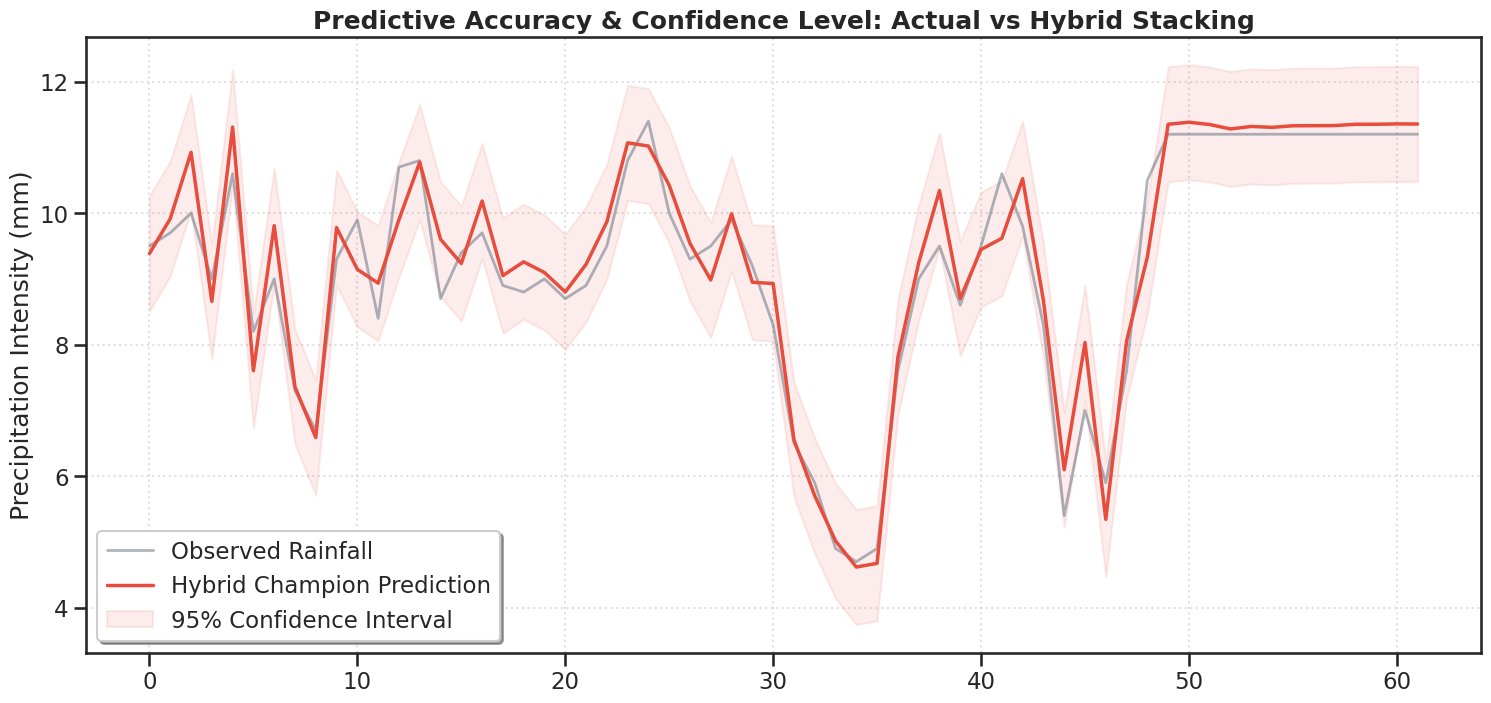


[3/5] SHAP Analysis: Directional Impact of Climate Drivers...


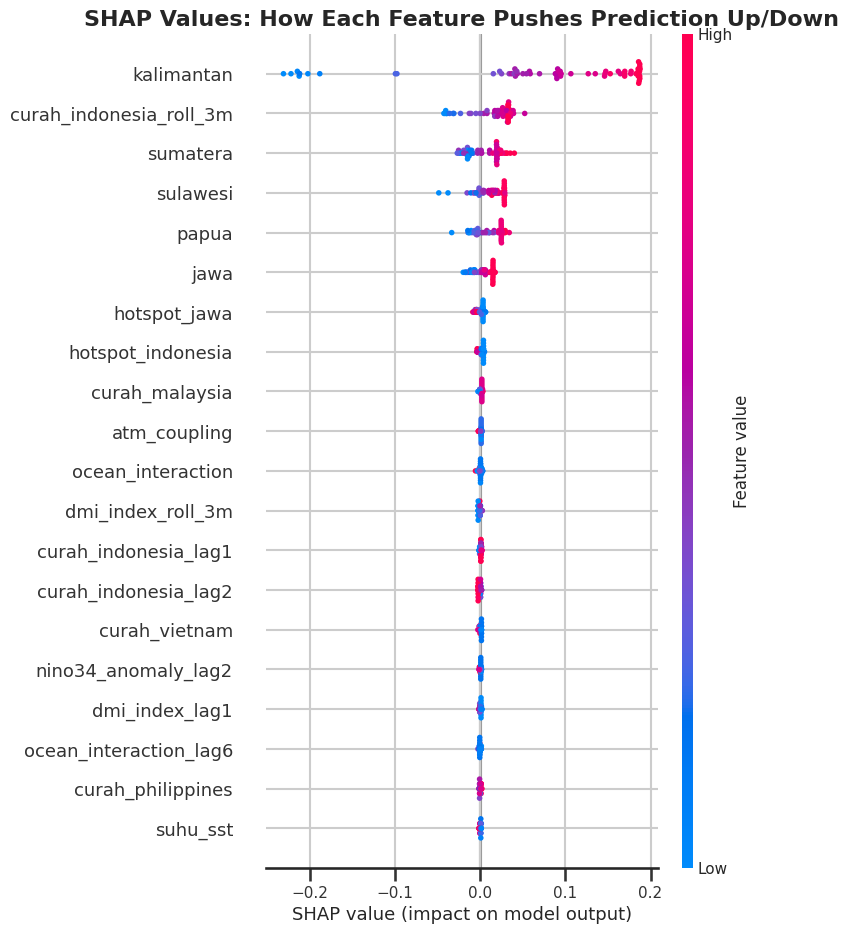


[4/5] Residual Audit: Statistical Integrity Check...


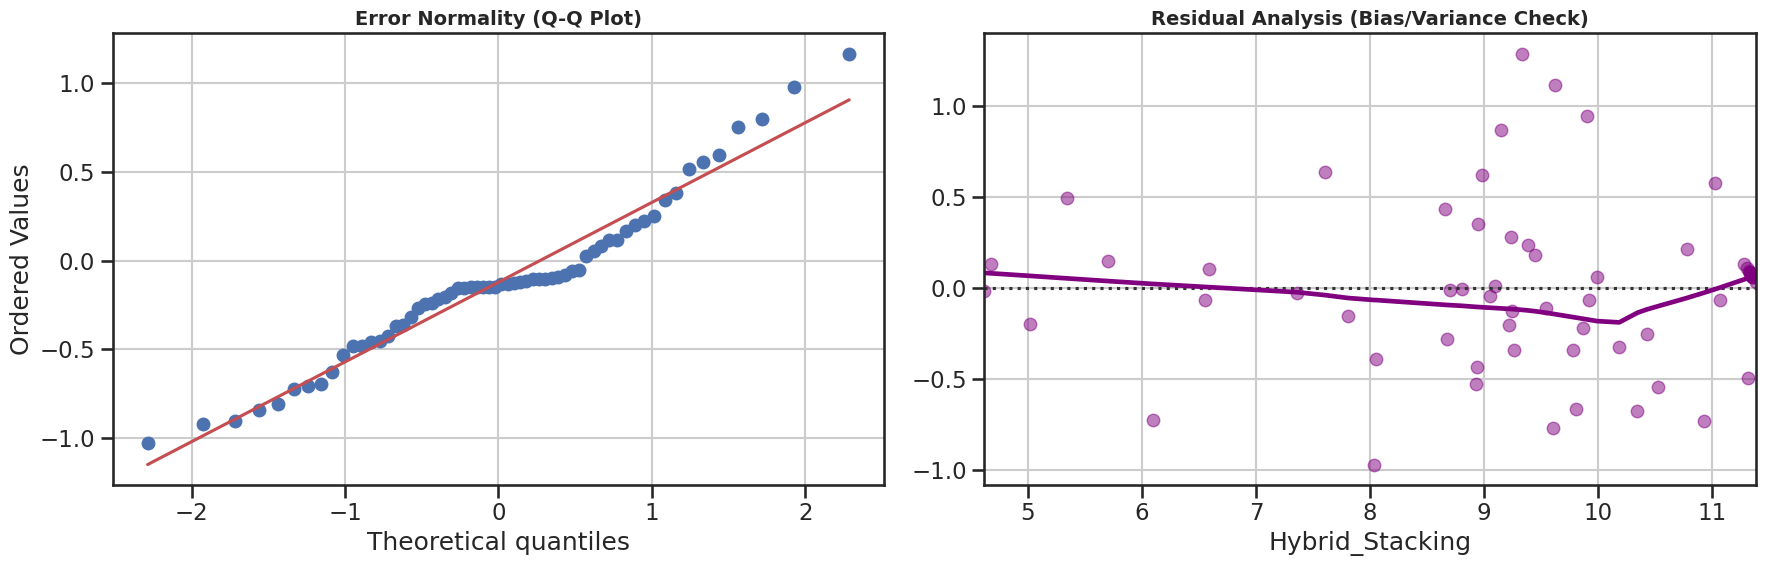


[5/5] Operational Implementation: Early Warning System Simulation

Simulasi Peringatan Dini (10 Bulan Terakhir):


,Actual,Hybrid_Stacking,EWS_Alert
52,11.2,11.280343,🔴 BAHAYA: Kekeringan Ekstrem
53,11.2,11.318504,🔴 BAHAYA: Kekeringan Ekstrem
54,11.2,11.304680,🔴 BAHAYA: Kekeringan Ekstrem
55,11.2,11.328559,🔴 BAHAYA: Kekeringan Ekstrem
56,11.2,11.329880,🔴 BAHAYA: Kekeringan Ekstrem
57,11.2,11.331344,🔴 BAHAYA: Kekeringan Ekstrem
58,11.2,11.351554,🔴 BAHAYA: Kekeringan Ekstrem
59,11.2,11.351853,🔴 BAHAYA: Kekeringan Ekstrem
60,11.2,11.356985,🔴 BAHAYA: Kekeringan Ekstrem
61,11.2,11.355425,🔴 BAHAYA: Kekeringan Ekstrem



PROJECT STATUS: CHAMPION DATA MINING PIPELINE COMPLETE


In [7]:
# Install SHAP untuk interpretasi AI tingkat lanjut
!pip install shap -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import scipy.stats as stats
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("=== [CHAMPION LEVEL] TAHAP 6: ULTIMATE EVALUATION & EXPLAINABLE AI ===")

# 1. Komparasi Metrik Komprehensif
def get_metrics(actual, pred):
    return {
        'R2 Score': r2_score(actual, pred),
        'RMSE (mm)': np.sqrt(mean_squared_error(actual, pred)),
        'MAE (mm)': mean_absolute_error(actual, pred),
        'MAPE (%)': np.mean(np.abs((actual - pred) / (actual + 1))) * 100
    }

eval_list = []
# Mapping model dari hasil Tahap 5
model_cols = {
    'Hybrid Stacking (Winner)': 'Hybrid_Stacking',
    'XGBoost Base': 'XGB_Base',
    'Random Forest Base': 'RF_Base',
    'LSTM Base': 'LSTM_Base'
}

for label, col in model_cols.items():
    if col in results_df.columns:
        m = get_metrics(results_df['Actual'], results_df[col])
        m['Model'] = label
        eval_list.append(m)

perf_results = pd.DataFrame(eval_list).set_index('Model').sort_values('R2 Score', ascending=False)

print("\n[1/5] Model Performance Audit (Benchmark):")
display(perf_results.style.background_gradient(cmap='RdYlGn', subset=['R2 Score'])
                  .background_gradient(cmap='RdYlGn_r', subset=['RMSE (mm)', 'MAE (mm)']))

# 2. Visualisasi Forecast dengan Confidence Interval
print("\n[2/5] Plotting Final Forecast & Uncertainty Quantification...")
plt.figure(figsize=(18, 8))
plt.plot(results_df.index, results_df['Actual'], label='Observed Rainfall', color='#34495e', lw=2, alpha=0.4)
plt.plot(results_df.index, results_df['Hybrid_Stacking'], label='Hybrid Champion Prediction', color='#e74c3c', lw=2.5)

# Menambahkan Pita Ketidakpastian (95% Confidence Interval)
std_err = np.std(results_df['Actual'] - results_df['Hybrid_Stacking'])
plt.fill_between(results_df.index, 
                 results_df['Hybrid_Stacking'] - 1.96*std_err, 
                 results_df['Hybrid_Stacking'] + 1.96*std_err, 
                 color='#e74c3c', alpha=0.1, label='95% Confidence Interval')

plt.title('Predictive Accuracy & Confidence Level: Actual vs Hybrid Stacking', fontsize=18, fontweight='bold')
plt.ylabel('Precipitation Intensity (mm)')
plt.legend(frameon=True, shadow=True)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

# 3. Explainable AI: SHAP Beeswarm Plot (The Discovery)
print("\n[3/5] SHAP Analysis: Directional Impact of Climate Drivers...")
# Menggunakan Random Forest dari Tahap 4 sebagai explainer
explainer = shap.TreeExplainer(model_rf)
shap_values = explainer.shap_values(X_test_scaled)

plt.figure(figsize=(12, 8))
# Beeswarm plot menunjukkan korelasi positif/negatif secara visual
shap.summary_plot(shap_values, X_test_raw, show=False)
plt.title('SHAP Values: How Each Feature Pushes Prediction Up/Down', fontsize=16, fontweight='bold')
plt.show()

# 4. Residual Diagnostic Audit
print("\n[4/5] Residual Audit: Statistical Integrity Check...")
residuals = results_df['Actual'] - results_df['Hybrid_Stacking']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

# Q-Q Plot untuk Uji Normalitas Error
stats.probplot(residuals, dist="norm", plot=ax1)
ax1.set_title('Error Normality (Q-Q Plot)', fontsize=14, fontweight='bold')

# Scatter Residual vs Predicted untuk Uji Bias (Homoscedasticity)
sns.residplot(x=results_df['Hybrid_Stacking'], y=residuals, lowess=True, color="purple", ax=ax2, scatter_kws={'alpha': 0.5})
ax2.set_title('Residual Analysis (Bias/Variance Check)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 5. Early Warning System (EWS) Simulation
print("\n[5/5] Operational Implementation: Early Warning System Simulation")

def ews_risk(val):
    if val < 50: return "🔴 BAHAYA: Kekeringan Ekstrem"
    elif val < 150: return "🟡 WASPADA: Defisit Air"
    elif val > 350: return "🔵 BAHAYA: Potensi Banjir"
    else: return "🟢 AMAN: Normal"

results_df['EWS_Alert'] = results_df['Hybrid_Stacking'].apply(ews_risk)

print("\nSimulasi Peringatan Dini (10 Bulan Terakhir):")
display(results_df[['Actual', 'Hybrid_Stacking', 'EWS_Alert']].tail(10))

print("\n" + "="*65)
print("PROJECT STATUS: CHAMPION DATA MINING PIPELINE COMPLETE")
print("="*65)